# 20nodes_EB_obsconf0_latconf0_Gaussian_Mixed: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf0_latconf0_Gaussian_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.480444,0.069760,15
1,DAGMA_Linear,0.138450,0.076816,15
2,DAGMA_Nonlinear,0.297817,0.064166,15
3,DAS,0.294669,0.080694,15
4,DirectLiNGAM,0.207968,0.113600,15
5,FCI,0.154243,0.070595,15
6,GES,0.573463,0.093367,15
7,GOLEM,0.136337,0.069971,15
8,GRaSP,0.586375,0.090946,15
9,GraNDAG,0.059634,0.053318,15


,model,mean,std,size
0,AVICI,44.800000,6.049793,15
1,DAGMA_Linear,57.666667,8.474050,15
2,DAGMA_Nonlinear,51.066667,6.782143,15
3,DAS,67.533333,13.075969,15
4,DirectLiNGAM,82.600000,23.200369,15
5,FCI,51.973333,10.092675,15
6,GES,40.200000,11.742475,15
7,GOLEM,62.666667,8.599557,15
8,GRaSP,34.808889,8.719832,15
9,GraNDAG,56.000000,5.744563,15


,model,mean,std,size
0,AVICI,0.671988,0.082322,15
1,DAGMA_Linear,0.245528,0.131100,15
2,DAGMA_Nonlinear,0.469713,0.081114,15
3,DAS,0.283061,0.079764,15
4,DirectLiNGAM,0.188666,0.117602,15
5,FCI,0.902451,0.175850,15
6,GES,0.619288,0.139448,15
7,GOLEM,0.201055,0.107780,15
8,GRaSP,0.809056,0.103790,15
9,GraNDAG,0.324673,0.245525,15


,model,mean,std,size
0,AVICI,0.382279,0.086409,15
1,DAGMA_Linear,0.097615,0.055842,15
2,DAGMA_Nonlinear,0.222130,0.059690,15
3,DAS,0.309669,0.087064,15
4,DirectLiNGAM,0.236931,0.111407,15
5,FCI,0.086388,0.042567,15
6,GES,0.545541,0.086460,15
7,GOLEM,0.104321,0.053249,15
8,GRaSP,0.465480,0.087634,15
9,GraNDAG,0.034327,0.032845,15


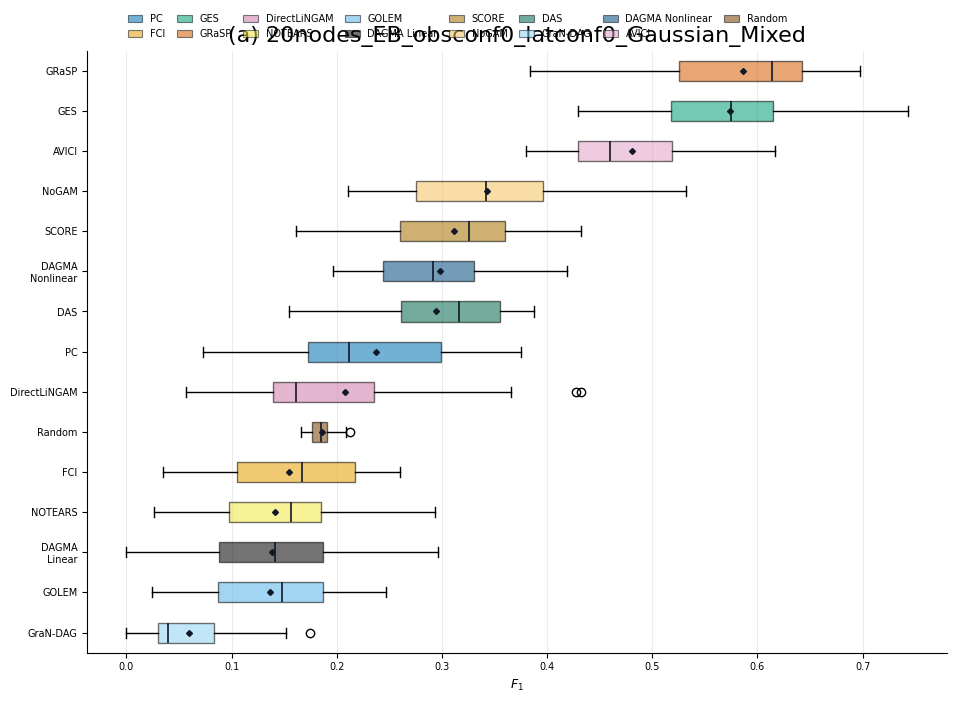

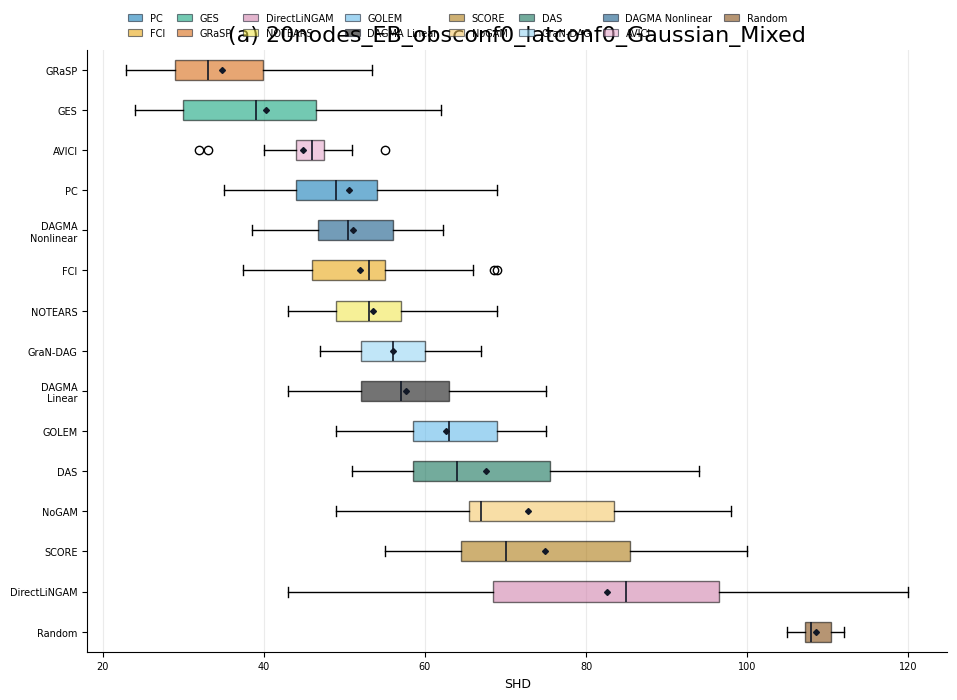

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.224158
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.035639
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.076923
9,13,GraNDAG,0.000000


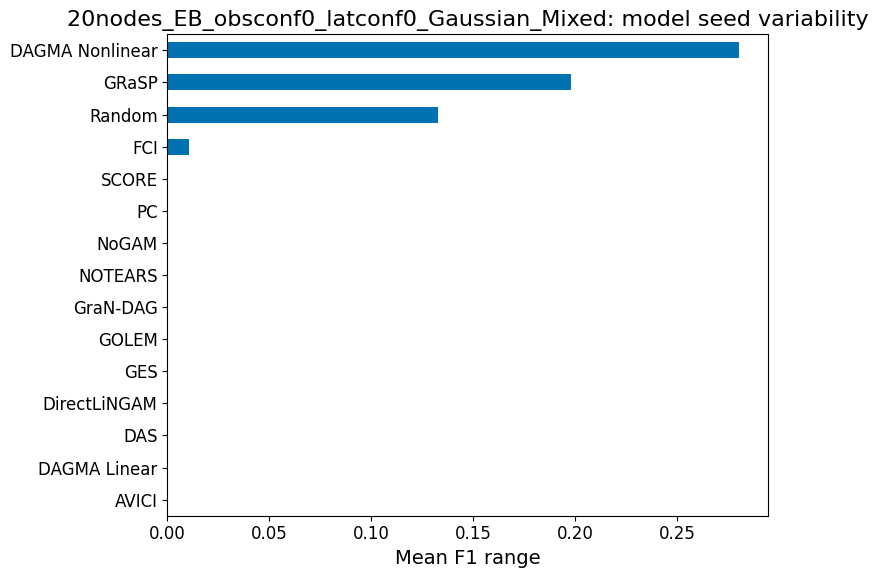

,model_seed,model,f1_range
0,0,AVICI,0.237076
1,0,DAGMA_Linear,0.296296
2,0,DAGMA_Nonlinear,0.354439
3,0,DAS,0.232167
4,0,DirectLiNGAM,0.376253
5,0,FCI,0.287218
6,0,GES,0.313733
7,0,GOLEM,0.223095
8,0,GRaSP,0.288304
9,0,GraNDAG,0.175000


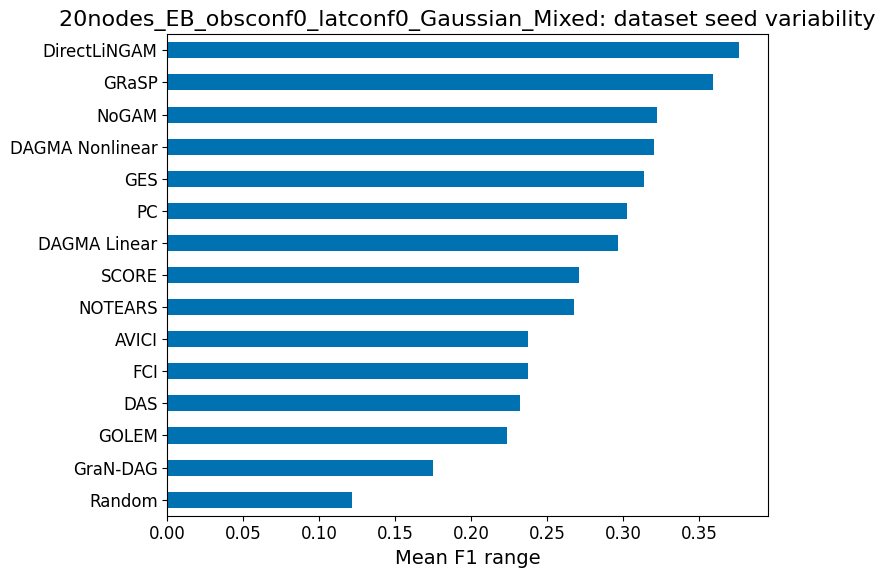

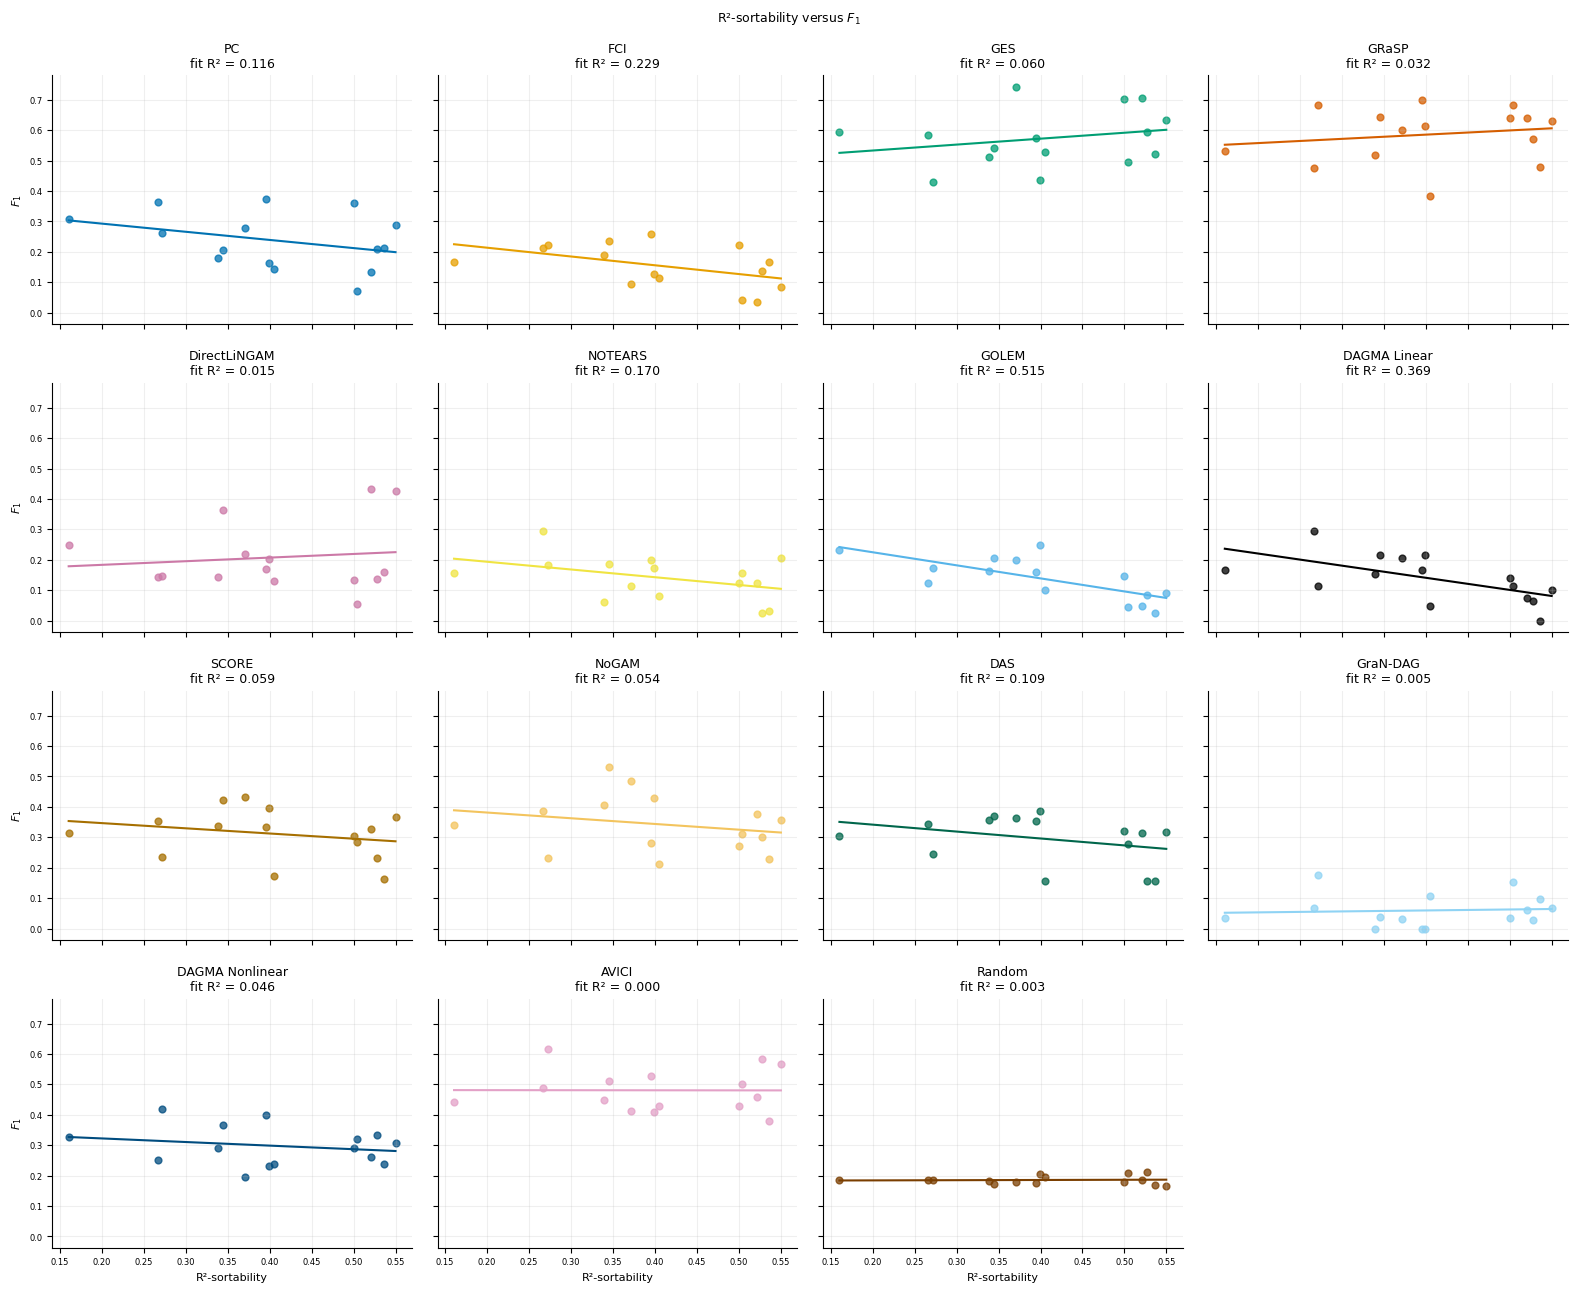

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,0.567901,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,0.100000,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,0.307896,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,0.316667,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,0.427184,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,0.084976,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,0.634146,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,0.089888,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,0.630769,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,0.067797,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.660232,0.266409,259,171,0,69,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.889655,0.344828,145,129,0,50,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.808290,0.160622,193,156,0,31,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.883019,0.520755,265,234,0,138,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.780488,0.395122,205,160,0,81,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.809375,0.271875,320,259,0,87,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.692737,0.405028,358,248,0,145,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.813107,0.500000,412,335,0,206,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.840855,0.527316,421,354,0,222,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,-0.004029,0.000016,-0.002406,0.481421,0.988629,-0.025000,0.929529
1,DAGMA_Linear,15,-0.607127,0.368604,-0.399131,0.300505,0.016385,-0.725648,0.002197
2,DAGMA_Nonlinear,15,-0.215509,0.046444,-0.118345,0.345867,0.440480,-0.178571,0.524284
3,DAS,15,-0.329911,0.108842,-0.227836,0.387175,0.229798,-0.382143,0.159824
4,DirectLiNGAM,15,0.122680,0.015050,0.119271,0.159542,0.663148,-0.021429,0.939578
5,FCI,15,-0.478454,0.228918,-0.289064,0.271609,0.071210,-0.522362,0.045761
6,GES,15,0.244075,0.059573,0.195028,0.494278,0.380672,0.178571,0.524284
7,GOLEM,15,-0.717758,0.515177,-0.429810,0.310848,0.002586,-0.735714,0.001770
8,GRaSP,15,0.178574,0.031889,0.138989,0.529943,0.524279,0.082143,0.771029
9,GraNDAG,15,0.069713,0.004860,0.031810,0.046718,0.805006,0.157707,0.574566


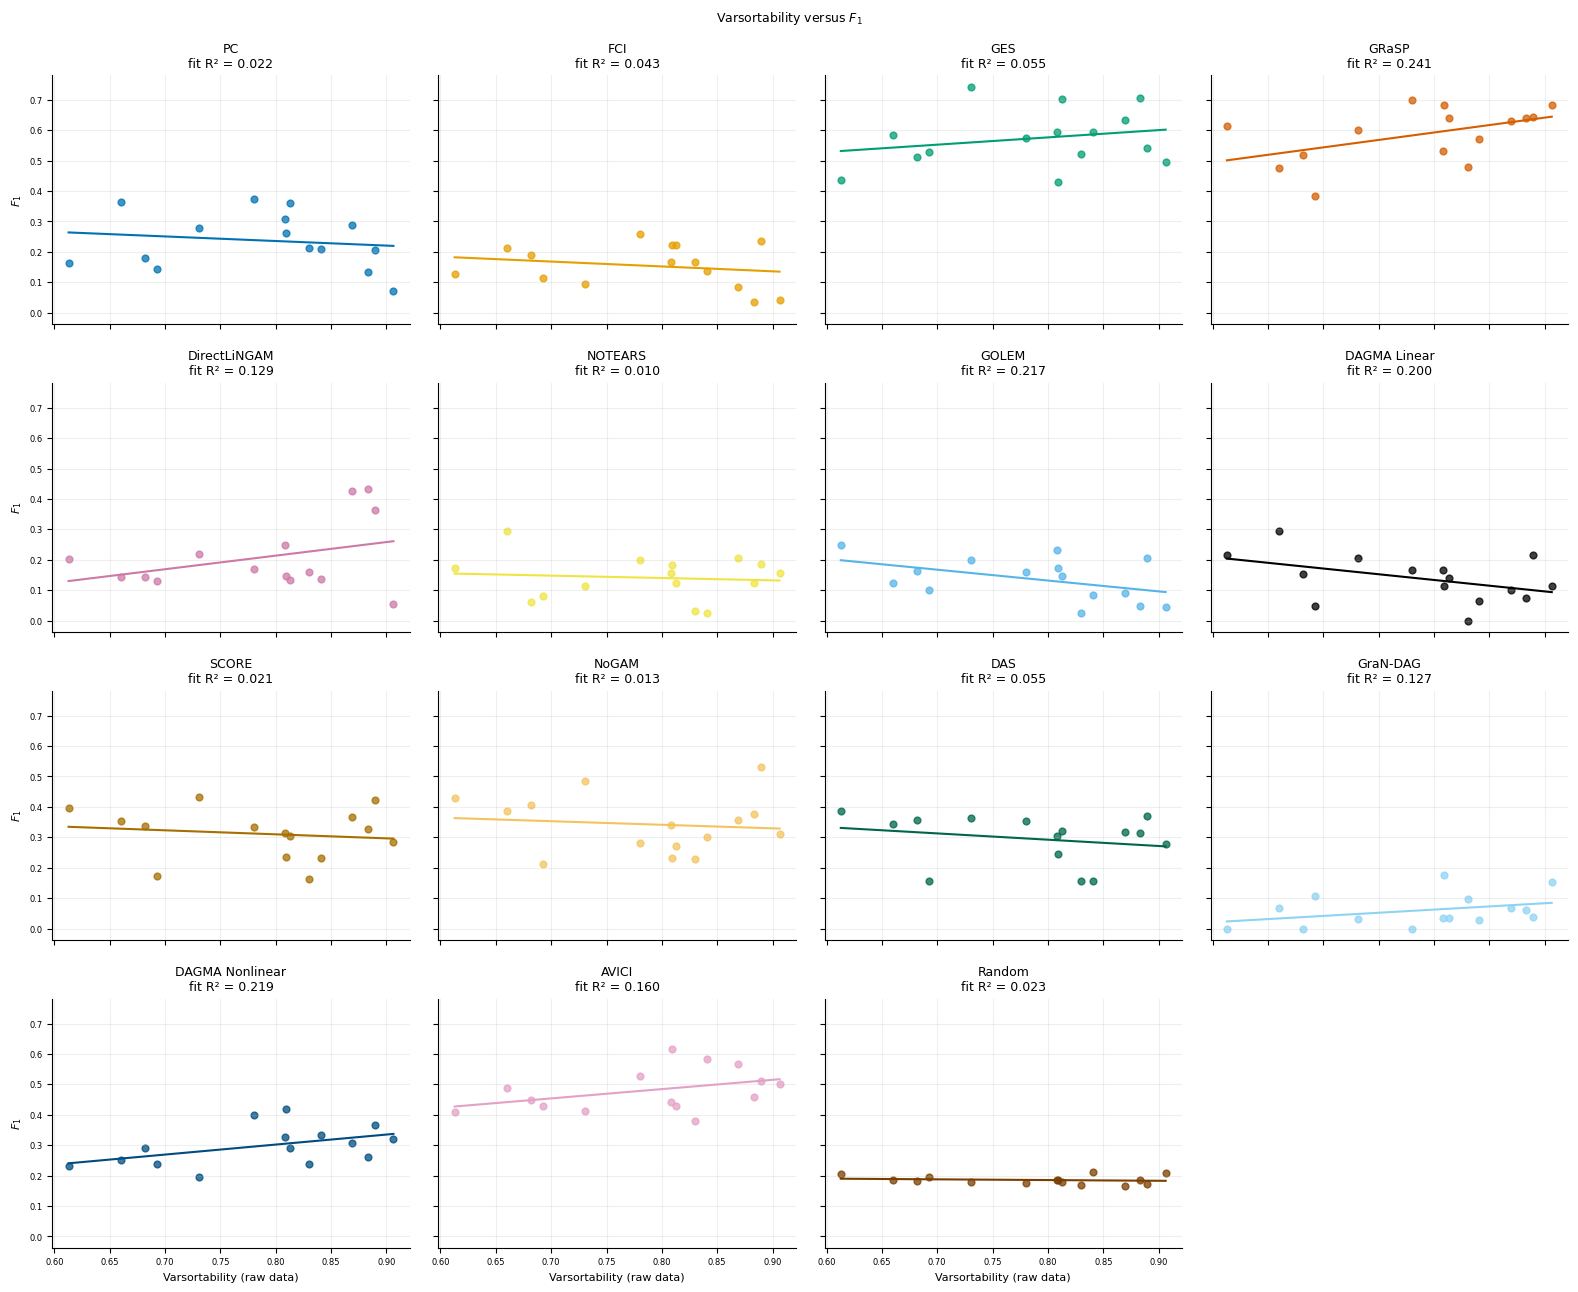

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,0.567901,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,0.100000,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,0.307896,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,0.316667,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,0.427184,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,0.084976,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,0.634146,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,0.089888,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,0.630769,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,0.067797,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.660232,0.266409,259,171,0,69,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.869110,0.549738,191,166,0,105,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.889655,0.344828,145,129,0,50,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.808290,0.160622,193,156,0,31,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.883019,0.520755,265,234,0,138,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.780488,0.395122,205,160,0,81,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.809375,0.271875,320,259,0,87,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.692737,0.405028,358,248,0,145,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.813107,0.500000,412,335,0,206,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.840855,0.527316,421,354,0,222,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.400001,0.160001,0.305759,0.239728,0.139594,0.425000,0.114295
1,DAGMA_Linear,15,-0.446942,0.199757,-0.376200,0.434622,0.094867,-0.416443,0.122567
2,DAGMA_Nonlinear,15,0.468352,0.219354,0.329298,0.038569,0.078272,0.453571,0.089486
3,DAS,15,-0.234103,0.054804,-0.206996,0.457632,0.401031,-0.342857,0.210924
4,DirectLiNGAM,15,0.358738,0.128693,0.446550,-0.143588,0.189157,0.164286,0.558497
5,FCI,15,-0.207535,0.043071,-0.160537,0.280630,0.457975,-0.225403,0.419251
6,GES,15,0.234172,0.054837,0.239575,0.384852,0.400887,0.178571,0.524284
7,GOLEM,15,-0.465471,0.216663,-0.356880,0.417299,0.080374,-0.500000,0.057699
8,GRaSP,15,0.490915,0.240997,0.489216,0.201229,0.063146,0.510714,0.051725
9,GraNDAG,15,0.356621,0.127178,0.208350,-0.104394,0.191972,0.412189,0.126828


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_Gaussian_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,AVICI,r2_sortability,15,-0.025000,0.929529,estimated,1.000000
1,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.725648,0.002197,estimated,0.030757
2,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,-0.178571,0.524284,estimated,1.000000
3,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DAS,r2_sortability,15,-0.382143,0.159824,estimated,1.000000
4,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,DirectLiNGAM,r2_sortability,15,-0.021429,0.939578,estimated,1.000000
5,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,FCI,r2_sortability,15,-0.522362,0.045761,estimated,0.594891
6,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GES,r2_sortability,15,0.178571,0.524284,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GOLEM,r2_sortability,15,-0.735714,0.001770,estimated,0.026548
8,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GRaSP,r2_sortability,15,0.082143,0.771029,estimated,1.000000
9,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,GraNDAG,r2_sortability,15,0.157707,0.574566,estimated,1.000000
